**Aim:** Differential Expression (DE) analysis comparing cells from different conditions (i.e. MDMA, Meth, Saline).
**Tools**
- `limma` – gene level 
- `iPAGE` – pathway level

# Differential analysis 

> Many methods have been used to determine differential gene expression from single-cell RNA (scRNA)-seq data. 

> Prefiltering of lowly expressed genes has important effects, particularly for some of the methods developed for bulk RNA-seq data analysis. However, we found that bulk RNA-seq analysis methods do not generally perform worse than those developed specifically for scRNA-seq. 

Source: [Soneson, C., Robinson, M. Bias, **robustness and scalability in single-cell differential expression analysis.** Nat Methods 15, 255–261 (2018).](https://doi.org/10.1038/nmeth.4612)

Also see 
[Wang, T., Li, B., Nelson, C.E. et al. **Comparative analysis of differential gene expression analysis tools for single-cell RNA sequencing data.** BMC Bioinformatics 20, 40 (2019).](https://doi.org/10.1186/s12859-019-2599-6)


[course chapter 12: Differential Expression (DE) analysis](https://biocellgen-public.svi.edu.au/mig_2019_scrnaseq-workshop/public/dechapter.html)


I'm also discussing this topic here https://github.com/abearab/sc-haircut-net/issues/3#issuecomment-832263091

> ### Estimate dispersion and DE using `DESeq2`
> Van den Berge and Perraudeau and others have shown the LRT may perform better for null hypothesis testing, so we use the LRT. In order to use the Wald test, it is recommended to set `useT=TRUE`.

> ### Plot dispersion estimates
> It is recommended to plot the dispersion estimates for DESeq2 on single-cell data. As discussed in the DESeq2 paper, it becomes difficult to accurately estimate the dispersion when the counts are very small, because the Poisson component of the variance is dominant. Therefore we see some very low dispersion estimates here, although the trend is still accurately capturing the upper proportion. So here everything looks good.


> If the parametric trend fails to fit (there would be a warning in this case), one should check the dispersion plot as above. If it looks like the dispersion fit is being thrown off by the low count genes with low dispersion estimates at the bottom of the plot, there is a relatively easy solution: one can filter out more of the low count genes only for the dispersion estimation step, so that the trend still captures the upper portion. This is pretty easy to do in DESeq2, to filter genes solely for the dispersion trend estimation, but to use a larger set for the rest of the analysis. An example of how this can be done:


In [2]:
import pandas as pd 
import scanpy as sc

In [3]:
def prep_diffexp_input(adata,name):
    counts = pd.DataFrame(
        adata.layers["counts"].T,
        columns = adata.obs.index.tolist(),
        index = adata.var.index.tolist()
    )

    meta = adata.obs[['batch','group']].copy()

    meta['treat'] = meta.batch.str.contains('acute').replace({True:'acute',False:'not-acute'})
    meta['rep'] = meta.batch.str[-1]

    counts.to_csv(f'diffexp/{name}_counts.txt',  sep='\t')
    meta.to_csv(f'diffexp/{name}_meta.txt',sep='\t')

___

`deseq` R env

In [8]:
source('plots.R')

draw_volcano <- function(name,xlim=10,lfc.cutoff = 1, pval.cutoff = 0.05){
    read.table(paste0('diffexp/',name,'/delta_exp_MDMAvsSaline.txt')) %>% 
        plot_Volcano (x_min=-xlim,x_max=xlim,lfc.cutoff = lfc.cutoff, pval.cutoff = pval.cutoff ) +
        ggtitle(paste0(name,'\nMDMAvsSaline'))  -> p1

    read.table(paste0('diffexp/',name,'/delta_exp_MDMAvsMeth.txt')) %>% 
        plot_Volcano (x_min=-xlim,x_max=xlim,lfc.cutoff = lfc.cutoff, pval.cutoff = pval.cutoff ) +
        ggtitle('MDMAvsMeth')  -> p2

    return(p1 / p2)
}

___

In [1]:
import blitzgsea as blitz

In [35]:
m5_gmt = blitz.enrichr.read_gmt('/data_gilbert/home/aarab/Projects/pager/annotations/mouse/m5.all.v0.3.symbols.gmt')

# Snap25_pos – Neurons

In [4]:
Snap25_pos  = sc.read_h5ad(
    'celltyping/Snap25_pos.h5ad.gz',
)

Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [5]:
Snap25_pos.var_names_make_unique()

In [6]:
Snap25_pos_counts = pd.DataFrame(
    Snap25_pos.layers["counts"].T,
    columns = Snap25_pos.obs.index.tolist(),
    index = Snap25_pos.var.index.tolist()
)

Snap25_pos_meta = Snap25_pos.obs[['batch','group']].copy()

Snap25_pos_meta['treat'] = Snap25_pos_meta.batch.str.contains('acute').replace({True:'acute',False:'not-acute'})
Snap25_pos_meta['rep'] = Snap25_pos_meta.batch.str[-1]

Snap25_pos_counts.to_csv('diffexp/Snap25_pos_counts.txt',  sep='\t')
Snap25_pos_meta.to_csv('diffexp/Snap25_pos_meta.txt',sep='\t')

___

`deseq` R env

In [1]:
!Rscript diffexp.R Snap25_pos

Warning message:
In dir.create(paste0("diffexp/", name)) :
  'diffexp/Snap25_pos' already exists


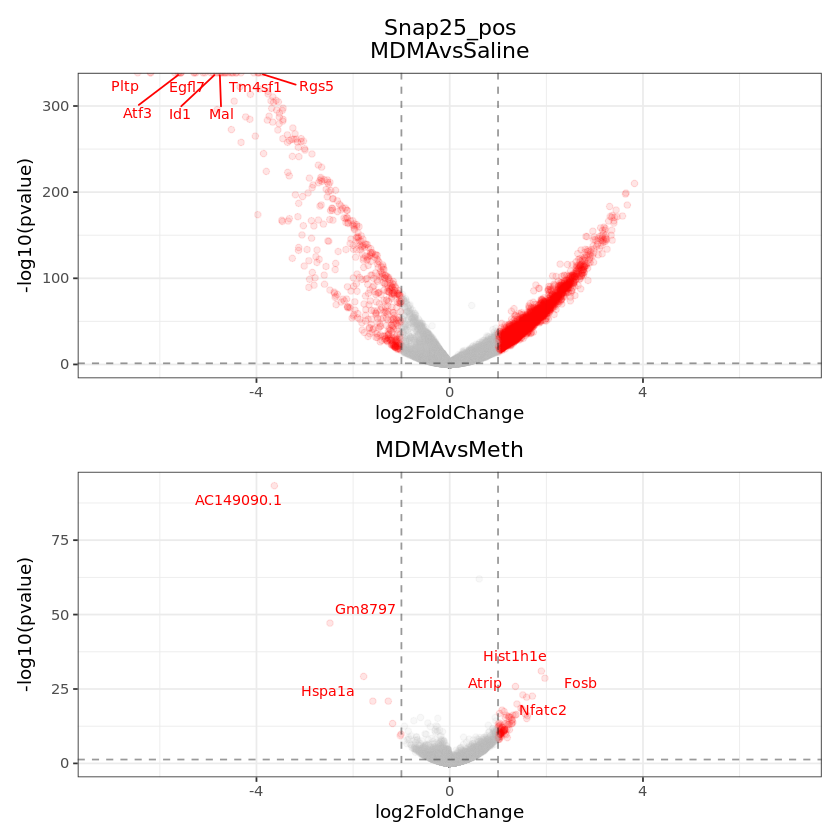

In [32]:
draw_volcano('Snap25_pos',7)


# Snap25_neg

In [4]:
Snap25_neg  = sc.read_h5ad(
    'celltyping/Snap25_neg-annotated.h5ad.gz',
)

In [7]:
Snap25_neg.obs.label

AAAGGGCCATTACGGT-1    Oligodendrocytes
AAAGGTAAGGGCAGGA-1         Endothelial
AAAGGTATCTCCGAAA-1    Oligodendrocytes
AAAGTCCTCACACCCT-1                OPCs
AAAGTGAGTGTATTGC-1    Oligodendrocytes
                            ...       
TTTGTTGAGCAACTTC-1    Oligodendrocytes
TTTGTTGAGGCCTTCG-1         Endothelial
TTTGTTGCACTGGCGT-1         Endothelial
TTTGTTGCAGGTCCGT-1         Endothelial
TTTGTTGGTTCTGAGT-1         Endothelial
Name: label, Length: 18222, dtype: category
Categories (8, object): ['13', 'Astrocytes', 'Endothelial', 'Microglia', 'OPCs', 'Oligodendrocytes', 'interneuron', 'neuroblast']

In [4]:
# Snap25_neg.var_names_make_unique()

## Astrocytes

In [8]:
Astrocytes = Snap25_neg[Snap25_neg.obs.label == 'Astrocytes'].copy()

In [9]:
prep_diffexp_input(Astrocytes,'Astrocytes')

___

`deseq` env

In [1]:
!Rscript diffexp.R Astrocytes

Warning message:
In dir.create(paste0("diffexp/", name)) :
  'diffexp/Astrocytes' already exists


___

`deseq` R env

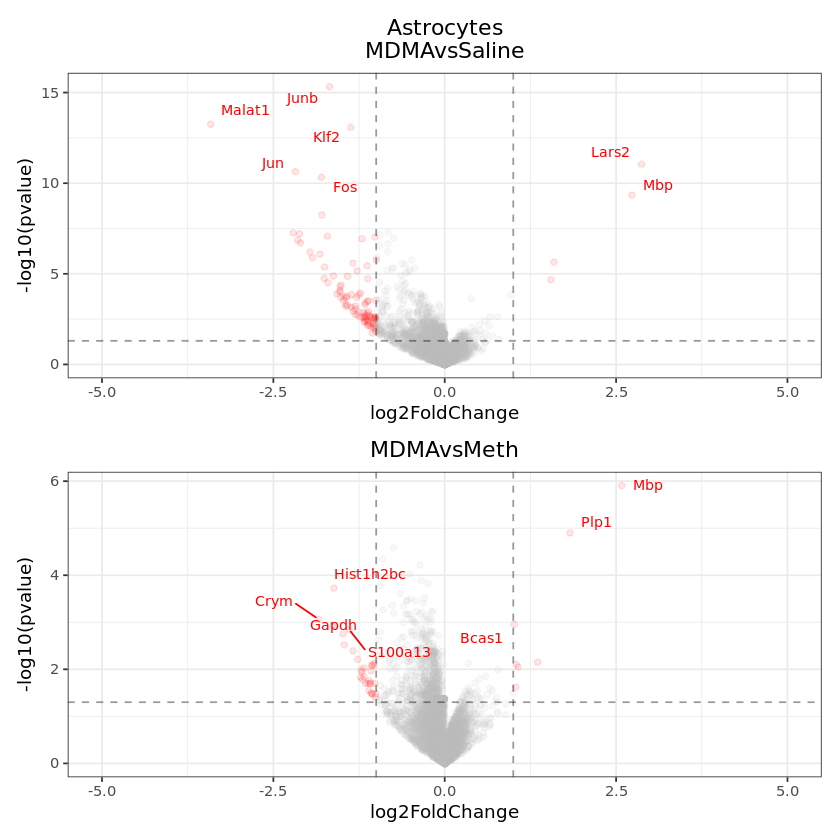

In [2]:
draw_volcano('Astrocytes',5)

In [ ]:
Astrocytes_MDMAvsSaline = pd.read_csv('diffexp/Astrocytes/delta_exp_MDMAvsSaline.txt',sep='\t')

In [ ]:
signature = Astrocytes_MDMAvsSaline[['log2FoldChange']].reset_index()
signature['index'] = signature['index'].str.upper()

gsea_result = blitz.gsea(
    signature,m5_gmt,
    min_size=5,
    verbose=True
)

In [ ]:
fig_table = blitz.plot.top_table(
    signature,m5_gmt,
    gsea_result[
        (gsea_result.nes < 0) & 
        (gsea_result.geneset_size < 50)
    ], n=15
)
# fig_table.savefig("gsea_top_nes_pos_table.pdf", bbox_inches='tight')
fig_table

In [ ]:
fig_table = blitz.plot.top_table(
    signature,m5_gmt,
    gsea_result[
        (gsea_result.nes > 0) & 
        (gsea_result.geneset_size < 50)
    ], n=15
)
# fig_table.savefig("gsea_top_nes_pos_table.pdf", bbox_inches='tight')
fig_table

## Microglia

In [10]:
Microglia = Snap25_neg[Snap25_neg.obs.label == 'Microglia'].copy()

In [11]:
prep_diffexp_input(Microglia,'Microglia')

___

`deseq` env

In [2]:
!Rscript diffexp.R Microglia

Warning message:
In dir.create(paste0("diffexp/", name)) :
  'diffexp/Microglia' already exists


___

`deseq` R env

Warning message:
“ggrepel: 1 unlabeled data points (too many overlaps). Consider increasing max.overlaps”
Warning message:
“ggrepel: 1 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


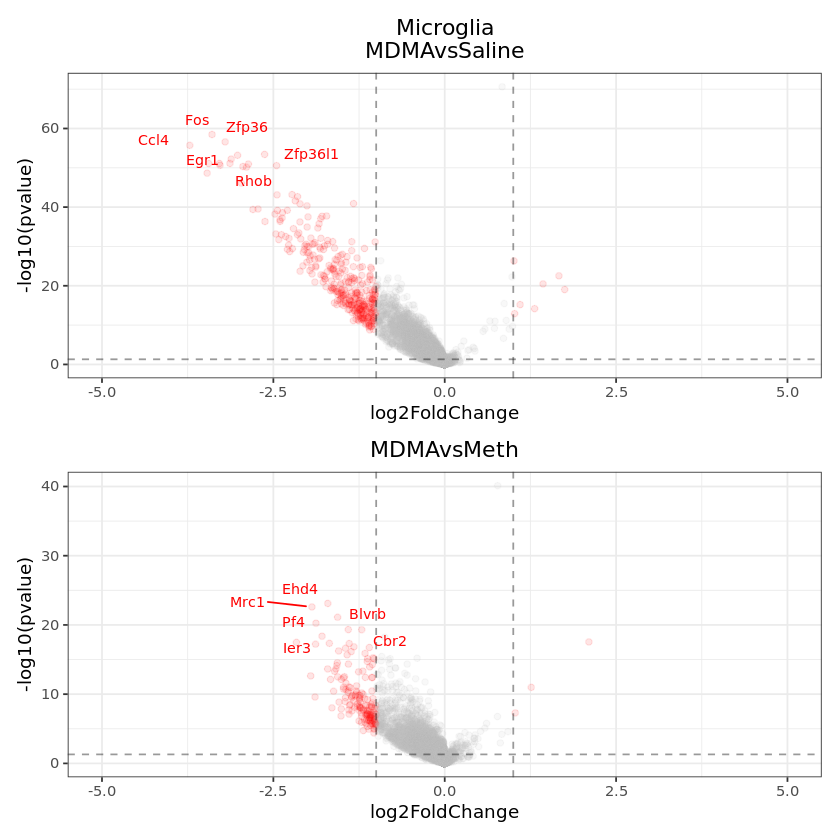

In [3]:
draw_volcano('Microglia',5)

## OPC

In [12]:
OPCs = Snap25_neg[Snap25_neg.obs.label == 'OPCs'].copy()

In [13]:
prep_diffexp_input(OPCs,'OPCs')

___

`deseq` env

In [3]:
!Rscript diffexp.R OPCs

Warning message:
In dir.create(paste0("diffexp/", name)) : 'diffexp/OPCs' already exists


___

`deseq` R env

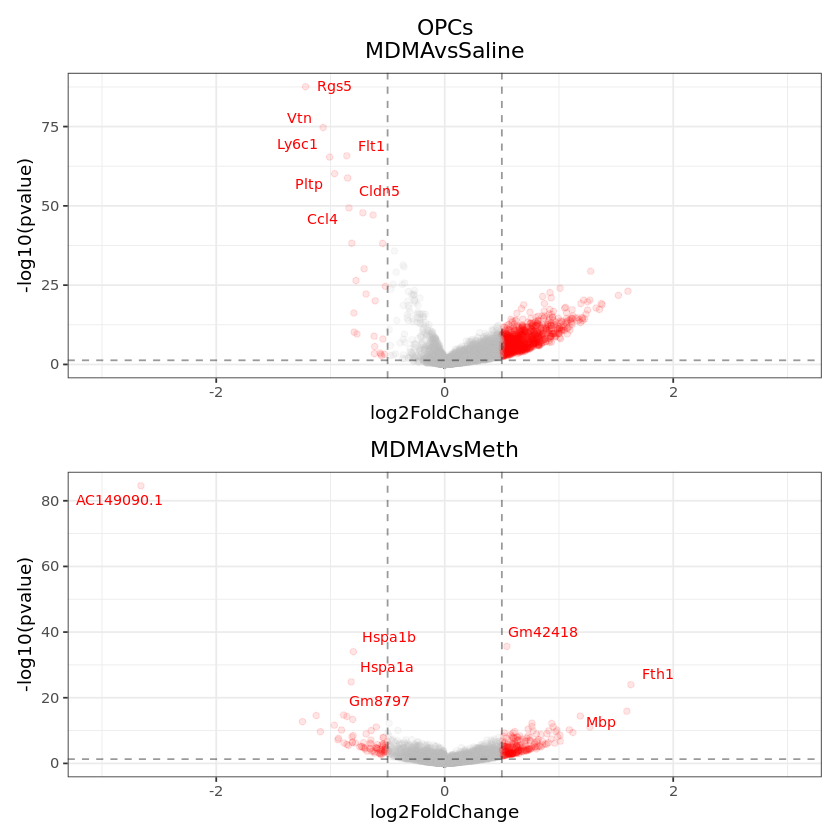

In [9]:
draw_volcano('OPCs',3,lfc.cutoff = 0.5)

## neuroblast

In [14]:
neuroblast = Snap25_neg[Snap25_neg.obs.label == 'neuroblast'].copy()

In [15]:
prep_diffexp_input(neuroblast,'neuroblast')

___

`deseq` env

In [4]:
!Rscript diffexp.R neuroblast

___

`deseq` R env

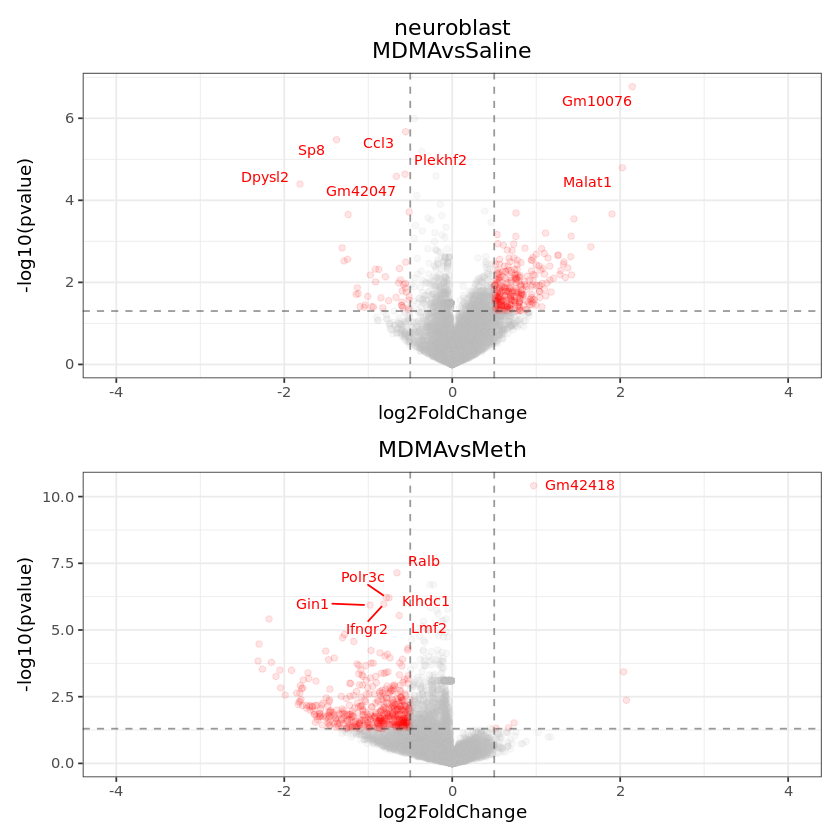

In [12]:
draw_volcano('neuroblast',4,lfc.cutoff = 0.5)

## Oligodendrocytes

In [16]:
Oligodendrocytes = Snap25_neg[Snap25_neg.obs.label == 'Oligodendrocytes'].copy()

In [17]:
prep_diffexp_input(Oligodendrocytes,'Oligodendrocytes')

___

`deseq` env

In [5]:
!Rscript diffexp.R Oligodendrocytes

Warning message:
In dir.create(paste0("diffexp/", name)) :
  'diffexp/Oligodendrocytes' already exists


___

`deseq` R env

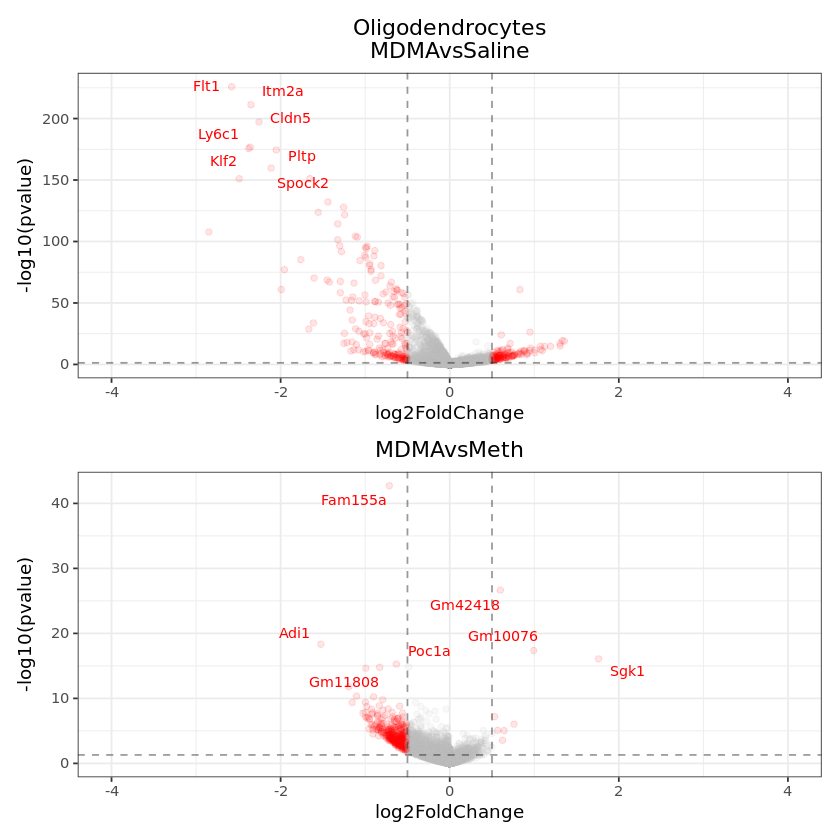

In [14]:
draw_volcano('Oligodendrocytes',4,lfc.cutoff = 0.5)

# Pathway analysis

___
__logFC__
___

__FDR__

https://github.com/goodarzilab/server_wiki/tree/main/lab_softwares
> FDR is calculated as `sign(logFC)*(1-Pvalue)`.

In [1]:
import pandas as pd
import numpy as np 

from glob import glob 

def fdr_diff_table(file):
    df = pd.read_csv(file,sep='\t')
    df['fdr'] = np.sign(df.log2FoldChange ) * (1 - df.pvalue)
    df.index = df.index.str.upper()
    df[['fdr']].to_csv(file.replace('.txt','_fdr.txt'),sep='\t')
    df[['log2FoldChange','pvalue','fdr']].to_csv(file.replace('.txt','_log2fc.txt'),sep='\t')

In [4]:
files = glob('diffexp/*/delta_exp*.txt')

for file in files:
    fdr_diff_table (file)


In [55]:
!cat ~/Projects/pager/ipage_loop.sh | head -n 2

## $1: input file contain table with first two columns as gene name/id and numeric value
pattern='msigdb_v0.3_m*'


In [12]:
%%bash 

export PAGEDIR='/data_gilbert/home/aarab/iPAGE'

for d in `ls -d diffexp/*/`; do 
    b=`basename $d`;
    echo $b
    cd $d;
    nohup ls *delta_exp*[log2fc,fdr].txt | parallel -j8 -k bash ~/Projects/pager/ipage_loop.sh {} &> /dev/null &
    cd ../../;
done

Astrocytes
Microglia
neuroblast
Oligodendrocytes
OPCs


In [ ]:
!rm -rv diffexp/*/*delta_exp*[log2fc,fdr].txt

___

In [ ]:
%%bash
zip -r diffexp/Snap25_pos_DE.zip diffexp/Snap25_pos_delta_exp_* 

zip -r diffexp/Astrocytes_DE.zip diffexp/Astrocytes_delta_exp_* 

zip -r diffexp/Microglia_DE.zip diffexp/Microglia_delta_exp_* 

zip -r diffexp/Oligodendrocytes_DE.zip diffexp/Oligodendrocytes_delta_exp_* 

zip -r diffexp/OPC_DE.zip diffexp/OPC_delta_exp_* 

#

In [13]:
!date

Wed Aug 10 21:31:32 PDT 2022
